# BÀI THỰC HÀNH 3.4: XÂY DỰNG VÀ THỬ NGHIỆM BỘ PHÂN LOẠI THƯ RÁC (SMS SPAM CLASSIFICATION)
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

---
### Mục tiêu bài thực hành:
1. Tiền xử lý và Vector hóa dữ liệu văn bản tin nhắn SMS bằng 2 phương pháp: **CountVectorizer** và **TfidfVectorizer** (giới hạn 5000 đặc trưng, loại bỏ stop words tiếng Anh).
2. Xây dựng chương trình thực nghiệm và so sánh hiệu năng 4 mô hình học máy:
   - **MLP (Multi-layer Perceptron / Neural Network)**
   - **Logistic Regression**
   - **Multinomial Naive Bayes (MultinomialNB)**
   - **Gaussian Process Classifier**
3. Đánh giá đa chiều với các chỉ số: **Accuracy, Precision (Spam), Recall (Spam), F1-Score (Spam), F1-Macro, ROC-AUC**.
4. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) và Đường cong đặc trưng hoạt động của bộ thu (ROC Curve).
5. Nhận xét và phân tích kết quả chuyên sâu.


## 1. Nạp tập dữ liệu SMS Spam Collection, khám phá phân bố và phân chia Train/Test (70% - 30%)


In [1]:
# ==============================================================================
# BƯỚC 1: NẠP DỮ LIỆU SMS SPAM COLLECTION VÀ PHÂN CHIA TẬP HUẤN LUYỆN / KIỂM THỬ
# ==============================================================================

# Import các thư viện cơ bản phục vụ xử lý dữ liệu và đo lường thời gian
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

# Đường dẫn tới tệp dữ liệu SMSSpamCollection
data_path = 'SMSSpamCollection'

# Đọc dữ liệu từ file phân tách bằng tab (\t), gán tên 2 cột: 'label' (nhãn) và 'message' (nội dung tin nhắn)
df = pd.read_csv(data_path, sep='\t', header=None, names=['label', 'message'])

# Mã hóa nhãn văn bản thành số: 'ham' (tin nhắn thường) = 0, 'spam' (tin nhắn rác) = 1
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# Thống kê số lượng mẫu và phân bố từng lớp
total_samples = len(df)
ham_count = (df['target'] == 0).sum()
spam_count = (df['target'] == 1).sum()

print("=== THỐNG KÊ TỔNG QUAN TẬP DỮ LIỆU SMS SPAM COLLECTION ===")
print(f"Tổng số tin nhắn SMS: {total_samples} tin")
print(f" - Tin nhắn thường (Ham - 0): {ham_count} tin ({ham_count / total_samples * 100:.2f}%)")
print(f" - Tin nhắn rác (Spam - 1):   {spam_count} tin ({spam_count / total_samples * 100:.2f}%)")

# Phân chia dữ liệu theo tỷ lệ 70% Train - 30% Test, sử dụng stratify để giữ nguyên tỷ lệ Ham/Spam
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['message'],
    df['target'],
    test_size=0.3,
    random_state=42,
    stratify=df['target']
)

print(f"\nSố lượng mẫu tập Huấn luyện (Train 70%): {len(X_train_raw)} tin nhắn")
print(f"Số lượng mẫu tập Kiểm thử (Test 30%):    {len(X_test_raw)} tin nhắn")


=== THỐNG KÊ TỔNG QUAN TẬP DỮ LIỆU SMS SPAM COLLECTION ===
Tổng số tin nhắn SMS: 5572 tin
 - Tin nhắn thường (Ham - 0): 4825 tin (86.59%)
 - Tin nhắn rác (Spam - 1):   747 tin (13.41%)

Số lượng mẫu tập Huấn luyện (Train 70%): 3900 tin nhắn
Số lượng mẫu tập Kiểm thử (Test 30%):    1672 tin nhắn


## 2. Vector hóa dữ liệu văn bản với 2 phương án: CountVectorizer và TfidfVectorizer (5000 đặc trưng, loại bỏ Stop Words)


In [2]:
# ==============================================================================
# BƯỚC 2: VECTOR HÓA VĂN BẢN VỚI COUNTVECTORIZER VÀ TFIDFVECTORIZER
# ==============================================================================

# Import hai lớp trích xuất đặc trưng văn bản từ scikit-learn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# ------------------------------------------------------------------------------
# 2.1. Phương án 1: CountVectorizer (Mô hình túi từ - Bag of Words)
# Giữ lại 5000 từ vựng có tần suất cao nhất và loại bỏ từ dừng tiếng Anh
# ------------------------------------------------------------------------------
count_vectorizer = CountVectorizer(max_features=5000, stop_words='english')

# Học từ điển trên tập Train và biến đổi sang ma trận đếm tần số
X_train_count = count_vectorizer.fit_transform(X_train_raw)
# Biến đổi tập Test dựa trên từ điển đã học từ tập Train
X_test_count = count_vectorizer.transform(X_test_raw)

# ------------------------------------------------------------------------------
# 2.2. Phương án 2: TfidfVectorizer (Trọng số TF-IDF: Tần suất từ x Nghịch đảo tài liệu)
# Giữ lại 5000 từ vựng có trọng số cao nhất và loại bỏ từ dừng tiếng Anh
# ------------------------------------------------------------------------------
tfidf_vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')

# Học từ điển và tính trọng số TF-IDF trên tập Train
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_raw)
# Biến đổi tập Test sang ma trận TF-IDF
X_test_tfidf = tfidf_vectorizer.transform(X_test_raw)

print("=== KẾT QUẢ VECTOR HÓA DỮ LIỆU VĂN BẢN ===")
print(f"1. CountVectorizer: Ma trận Train {X_train_count.shape} | Ma trận Test {X_test_count.shape}")
print(f"2. TfidfVectorizer: Ma trận Train {X_train_tfidf.shape} | Ma trận Test {X_test_tfidf.shape}")
print(f"Số lượng đặc trưng từ vựng được trích xuất cho mỗi phương án: {X_train_count.shape[1]} thuộc tính")


=== KẾT QUẢ VECTOR HÓA DỮ LIỆU VĂN BẢN ===
1. CountVectorizer: Ma trận Train (3900, 5000) | Ma trận Test (1672, 5000)
2. TfidfVectorizer: Ma trận Train (3900, 5000) | Ma trận Test (1672, 5000)
Số lượng đặc trưng từ vựng được trích xuất cho mỗi phương án: 5000 thuộc tính


## 3. Xây dựng chương trình thực nghiệm và so sánh 4 mô hình (MLP, Logistic Regression, MultinomialNB, Gaussian Process)


In [3]:
# ==============================================================================
# BƯỚC 3: HUẤN LUYỆN VÀ ĐÁNH GIÁ 4 MÔ HÌNH TRÊN 2 PHƯƠNG ÁN VECTOR HÓA (8 THỰC NGHIỆM)
# ==============================================================================

# Import 4 thuật toán phân loại và các hàm đo lường hiệu năng
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# Định nghĩa hàm tạo mới 4 mô hình phân loại để đảm bảo tính độc lập giữa các thực nghiệm
def get_classifiers():
    return {
        'Multinomial Naive Bayes': MultinomialNB(),
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'MLP (Neural Net)': MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=42),
        'Gaussian Process': GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42, max_iter_predict=100)
    }

# Khởi tạo từ điển lưu trữ kết quả và dự đoán để vẽ biểu đồ
results_data = []
trained_objects = {}
predictions_data = {}
probabilities_data = {}

# Danh sách 2 kịch bản vector hóa
vectorizer_scenarios = [
    ('CountVectorizer', X_train_count, X_test_count),
    ('TfidfVectorizer', X_train_tfidf, X_test_tfidf)
]

print("=== BẮT ĐẦU CHẠY THỰC NGHIỆM 8 MÔ HÌNH PHÂN LOẠI ===")

# Duyệt qua từng phương pháp vector hóa
for vec_name, X_tr, X_te in vectorizer_scenarios:
    print(f"\n--- Đang thực thi với: {vec_name} ---")
    current_models = get_classifiers()
    
    # Duyệt qua từng mô hình phân loại
    for model_name, clf in current_models.items():
        t_start = time.time()
        
        # Gaussian Process yêu cầu đầu vào dạng mảng đặc (Dense Array)
        if model_name == 'Gaussian Process':
            X_tr_fit = X_tr.toarray()
            X_te_fit = X_te.toarray()
        else:
            X_tr_fit = X_tr
            X_te_fit = X_te
        
        # Huấn luyện mô hình trên tập Train
        clf.fit(X_tr_fit, y_train)
        t_train = time.time() - t_start
        
        # Dự đoán nhãn lớp và xác suất dự đoán trên tập Test
        y_pred = clf.predict(X_te_fit)
        
        # Lấy xác suất dự đoán cho lớp Spam (target = 1)
        if hasattr(clf, "predict_proba"):
            y_prob = clf.predict_proba(X_te_fit)[:, 1]
        else:
            y_prob = clf.decision_function(X_te_fit)
        
        # Lưu lại đối tượng và kết quả dự đoán
        key = f"{model_name} ({vec_name})"
        trained_objects[key] = clf
        predictions_data[key] = y_pred
        probabilities_data[key] = y_prob
        
        # Tính toán các chỉ số đo lường hiệu năng
        acc = accuracy_score(y_test, y_pred)
        prec_spam = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
        rec_spam = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
        f1_sp = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
        f1_mac = f1_score(y_test, y_pred, average='macro', zero_division=0)
        auc_val = roc_auc_score(y_test, y_prob)
        
        n_correct = int((y_pred == y_test).sum())
        n_wrong = int((y_pred != y_test).sum())
        
        # Thêm kết quả vào danh sách tổng hợp
        results_data.append({
            'Phương pháp Vector hóa': vec_name,
            'Thuật toán Mô hình': model_name,
            'Accuracy (%)': acc * 100,
            'Precision Spam (%)': prec_spam * 100,
            'Recall Spam (%)': rec_spam * 100,
            'F1-Score Spam (%)': f1_sp * 100,
            'F1-Macro (%)': f1_mac * 100,
            'ROC-AUC (%)': auc_val * 100,
            'Thời gian train (s)': t_train,
            'Đoán đúng': f"{n_correct}/{len(y_test)}"
        })
        
        print(f" -> {model_name:<25} | Acc: {acc*100:6.2f}% | Prec: {prec_spam*100:6.2f}% | Rec: {rec_spam*100:6.2f}% | F1-Spam: {f1_sp*100:6.2f}% | AUC: {auc_val*100:6.2f}% | Time: {t_train:5.2f}s")

# Chuyển kết quả sang DataFrame
df_summary = pd.DataFrame(results_data)

# Định dạng bảng hiển thị trực quan
df_display = df_summary.copy()
for col in ['Accuracy (%)', 'Precision Spam (%)', 'Recall Spam (%)', 'F1-Score Spam (%)', 'F1-Macro (%)', 'ROC-AUC (%)']:
    df_display[col] = df_display[col].map(lambda x: f"{x:.2f}%")
df_display['Thời gian train (s)'] = df_display['Thời gian train (s)'].map(lambda x: f"{x:.2f}s")

print("\n" + "=" * 100)
print("=== BẢNG TỔNG HỢP VÀ ĐỐI SÁNH HIỆU NĂNG 8 THỰC NGHIỆM PHÂN LOẠI THƯ RÁC ===")
print("=" * 100)
print(df_display.to_string(index=False))


=== BẮT ĐẦU CHẠY THỰC NGHIỆM 8 MÔ HÌNH PHÂN LOẠI ===

--- Đang thực thi với: CountVectorizer ---
 -> Multinomial Naive Bayes   | Acc:  98.56% | Prec:  96.30% | Rec:  92.86% | F1-Spam:  94.55% | AUC:  98.58% | Time:  0.00s
 -> Logistic Regression       | Acc:  97.55% | Prec:  99.46% | Rec:  82.14% | F1-Spam:  89.98% | AUC:  98.65% | Time:  0.01s
 -> MLP (Neural Net)          | Acc:  98.50% | Prec:  99.50% | Rec:  89.29% | F1-Spam:  94.12% | AUC:  97.31% | Time: 14.28s
 -> Gaussian Process          | Acc:  98.27% | Prec: 100.00% | Rec:  87.05% | F1-Spam:  93.08% | AUC:  97.97% | Time: 516.79s

--- Đang thực thi với: TfidfVectorizer ---
 -> Multinomial Naive Bayes   | Acc:  97.43% | Prec: 100.00% | Rec:  80.80% | F1-Spam:  89.38% | AUC:  98.67% | Time:  0.02s
 -> Logistic Regression       | Acc:  96.53% | Prec: 100.00% | Rec:  74.11% | F1-Spam:  85.13% | AUC:  98.67% | Time:  0.01s
 -> MLP (Neural Net)          | Acc:  98.39% | Prec:  97.13% | Rec:  90.62% | F1-Spam:  93.76% | AUC:  98.54

## 4. Trực quan hóa kết quả: Biểu đồ so sánh hiệu năng, Đường cong ROC-AUC và Ma trận nhầm lẫn


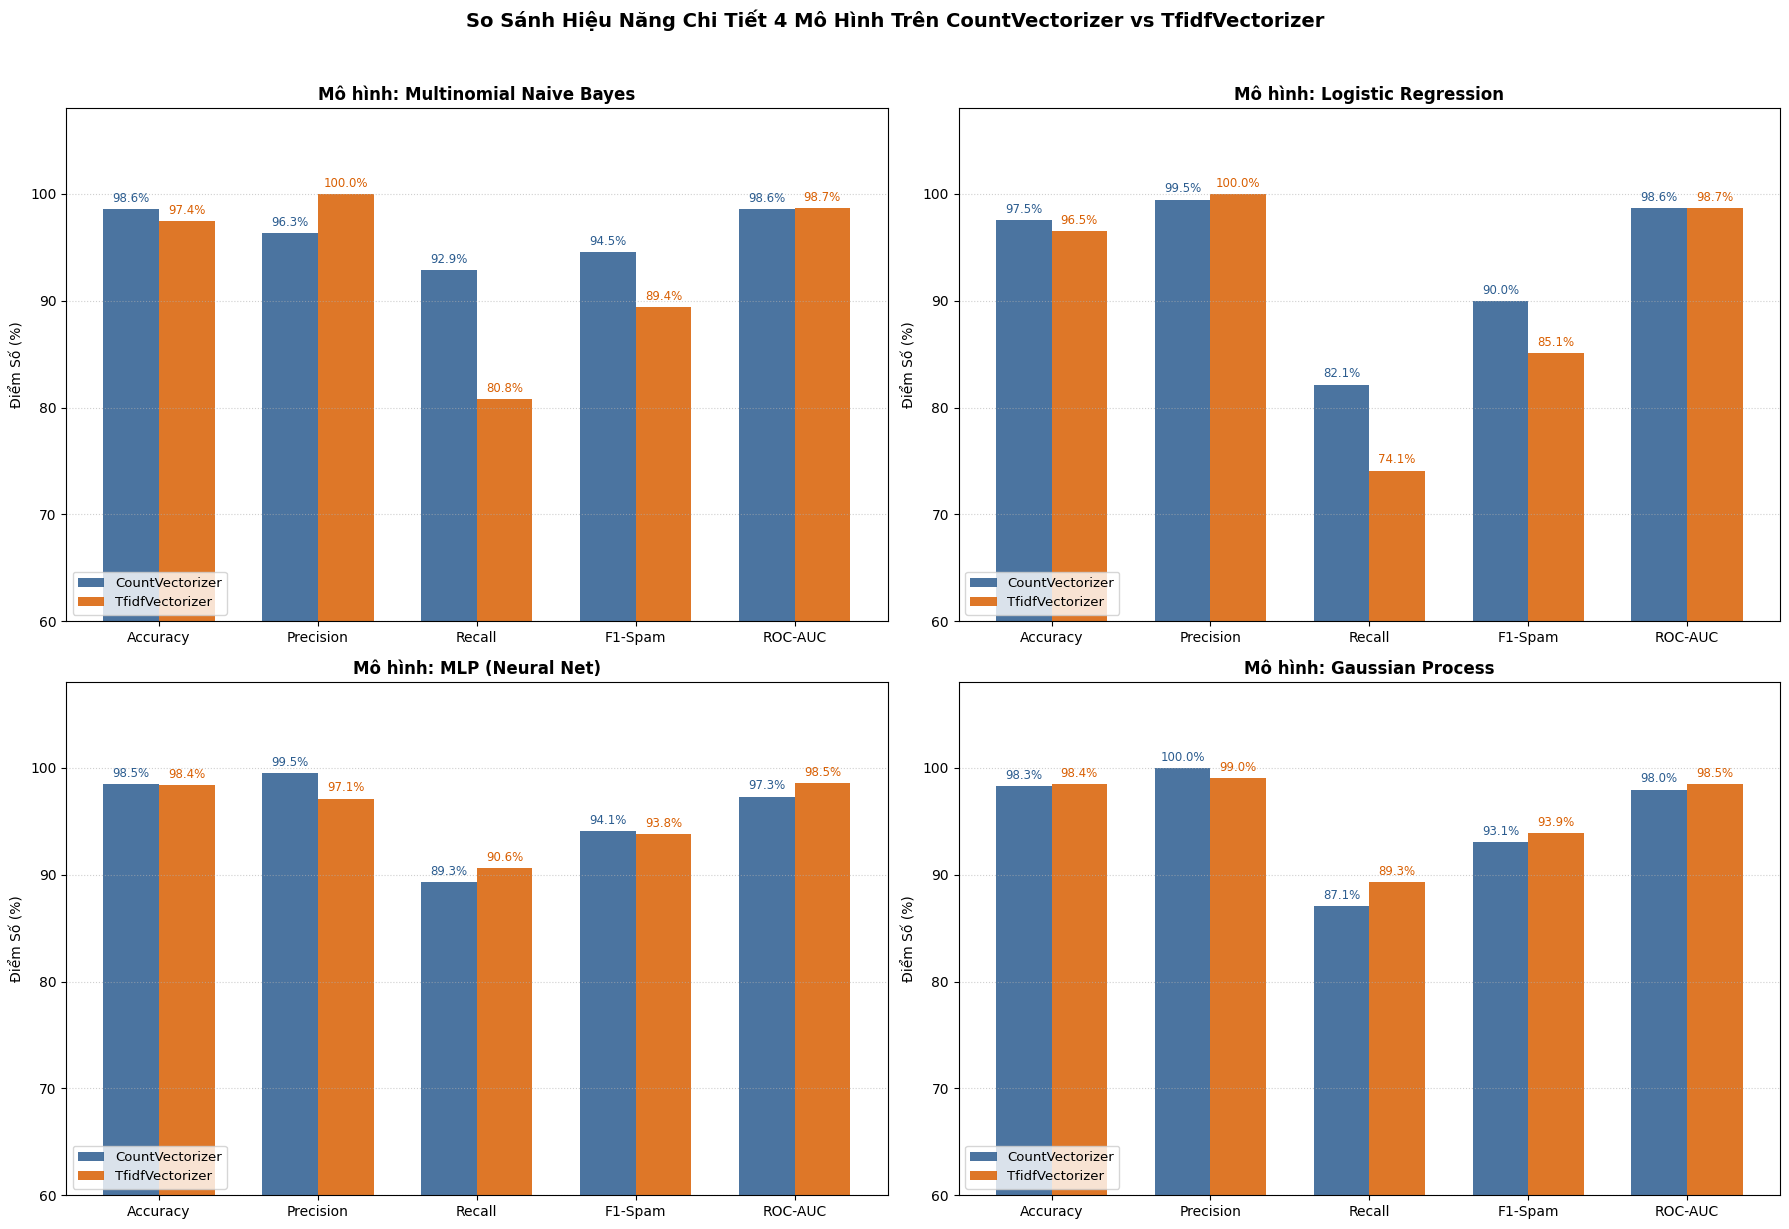

In [4]:
# ==============================================================================
# 4.1. VẼ BIỂU ĐỒ CỘT ĐỐI SÁNH HIỆU NĂNG GIỮA COUNTVECTORIZER VÀ TFIDFVECTORIZER
# ==============================================================================

# Thiết lập dữ liệu phục vụ vẽ biểu đồ nhóm
metrics_to_plot = ['Accuracy (%)', 'Precision Spam (%)', 'Recall Spam (%)', 'F1-Score Spam (%)', 'ROC-AUC (%)']
model_names_unique = ['Multinomial Naive Bayes', 'Logistic Regression', 'MLP (Neural Net)', 'Gaussian Process']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
axes_flat = axes.flatten()

# Lọc dữ liệu theo từng mô hình và vẽ so sánh
for idx, m_name in enumerate(model_names_unique):
    sub_df = df_summary[df_summary['Thuật toán Mô hình'] == m_name]
    
    x = np.arange(len(metrics_to_plot))
    width = 0.35
    
    count_vals = sub_df[sub_df['Phương pháp Vector hóa'] == 'CountVectorizer'][metrics_to_plot].values[0]
    tfidf_vals = sub_df[sub_df['Phương pháp Vector hóa'] == 'TfidfVectorizer'][metrics_to_plot].values[0]
    
    rects1 = axes_flat[idx].bar(x - width/2, count_vals, width, label='CountVectorizer', color='#2b5c8f', alpha=0.85)
    rects2 = axes_flat[idx].bar(x + width/2, tfidf_vals, width, label='TfidfVectorizer', color='#d95f02', alpha=0.85)
    
    # Ghi giá trị phần trăm lên đầu các cột
    for rect in rects1:
        h = rect.get_height()
        axes_flat[idx].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, color='#2b5c8f')
    
    for rect in rects2:
        h = rect.get_height()
        axes_flat[idx].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, color='#d95f02')
    
    axes_flat[idx].set_title(f"Mô hình: {m_name}", fontsize=12, fontweight='bold')
    axes_flat[idx].set_xticks(x)
    axes_flat[idx].set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1-Spam', 'ROC-AUC'], fontsize=10)
    axes_flat[idx].set_ylim(60, 108)
    axes_flat[idx].set_ylabel('Điểm Số (%)', fontsize=10)
    axes_flat[idx].grid(axis='y', linestyle=':', alpha=0.6)
    axes_flat[idx].legend(loc='lower left', fontsize=9.5)

plt.suptitle("So Sánh Hiệu Năng Chi Tiết 4 Mô Hình Trên CountVectorizer vs TfidfVectorizer", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


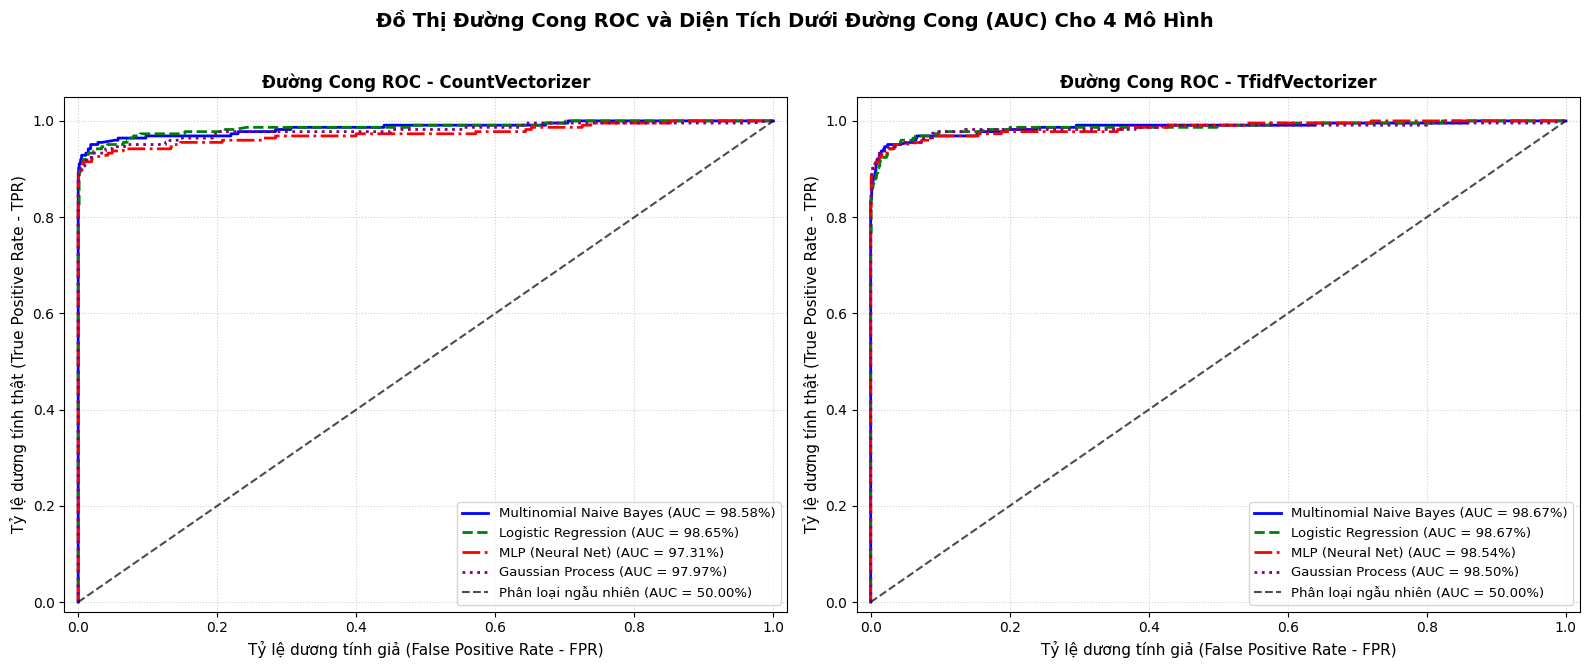

In [5]:
# ==============================================================================
# 4.2. VẼ ĐƯỜNG CONG ROC (RECEIVER OPERATING CHARACTERISTIC) VÀ TÍNH DIỆN TÍCH AUC
# ==============================================================================

# Khởi tạo khung hình chứa 2 biểu đồ ROC cạnh nhau (1 hàng, 2 cột)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6.5))

# Cấu hình màu sắc và kiểu đường vẽ cho từng mô hình
model_colors = {
    'Multinomial Naive Bayes': ('blue', '-'),
    'Logistic Regression': ('green', '--'),
    'MLP (Neural Net)': ('red', '-.'),
    'Gaussian Process': ('purple', ':')
}

# ------------------------------------------------------------------------------
# 4.2.1. Vẽ đường cong ROC cho các mô hình sử dụng CountVectorizer
# ------------------------------------------------------------------------------
for m_name, (col, ls) in model_colors.items():
    key = f"{m_name} (CountVectorizer)"
    y_prob = probabilities_data[key]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, color=col, linestyle=ls, linewidth=2, label=f"{m_name} (AUC = {auc_score*100:.2f}%)")

# Đường phân loại ngẫu nhiên (đường chéo baseline 50%)
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.7, label='Phân loại ngẫu nhiên (AUC = 50.00%)')
axes[0].set_title("Đường Cong ROC - CountVectorizer", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Tỷ lệ dương tính giả (False Positive Rate - FPR)", fontsize=11)
axes[0].set_ylabel("Tỷ lệ dương tính thật (True Positive Rate - TPR)", fontsize=11)
axes[0].set_xlim([-0.02, 1.02])
axes[0].set_ylim([-0.02, 1.05])
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right', fontsize=9.5)

# ------------------------------------------------------------------------------
# 4.2.2. Vẽ đường cong ROC cho các mô hình sử dụng TfidfVectorizer
# ------------------------------------------------------------------------------
for m_name, (col, ls) in model_colors.items():
    key = f"{m_name} (TfidfVectorizer)"
    y_prob = probabilities_data[key]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    axes[1].plot(fpr, tpr, color=col, linestyle=ls, linewidth=2, label=f"{m_name} (AUC = {auc_score*100:.2f}%)")

axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.7, label='Phân loại ngẫu nhiên (AUC = 50.00%)')
axes[1].set_title("Đường Cong ROC - TfidfVectorizer", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tỷ lệ dương tính giả (False Positive Rate - FPR)", fontsize=11)
axes[1].set_ylabel("Tỷ lệ dương tính thật (True Positive Rate - TPR)", fontsize=11)
axes[1].set_xlim([-0.02, 1.02])
axes[1].set_ylim([-0.02, 1.05])
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right', fontsize=9.5)

plt.suptitle("Đồ Thị Đường Cong ROC và Diện Tích Dưới Đường Cong (AUC) Cho 4 Mô Hình", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


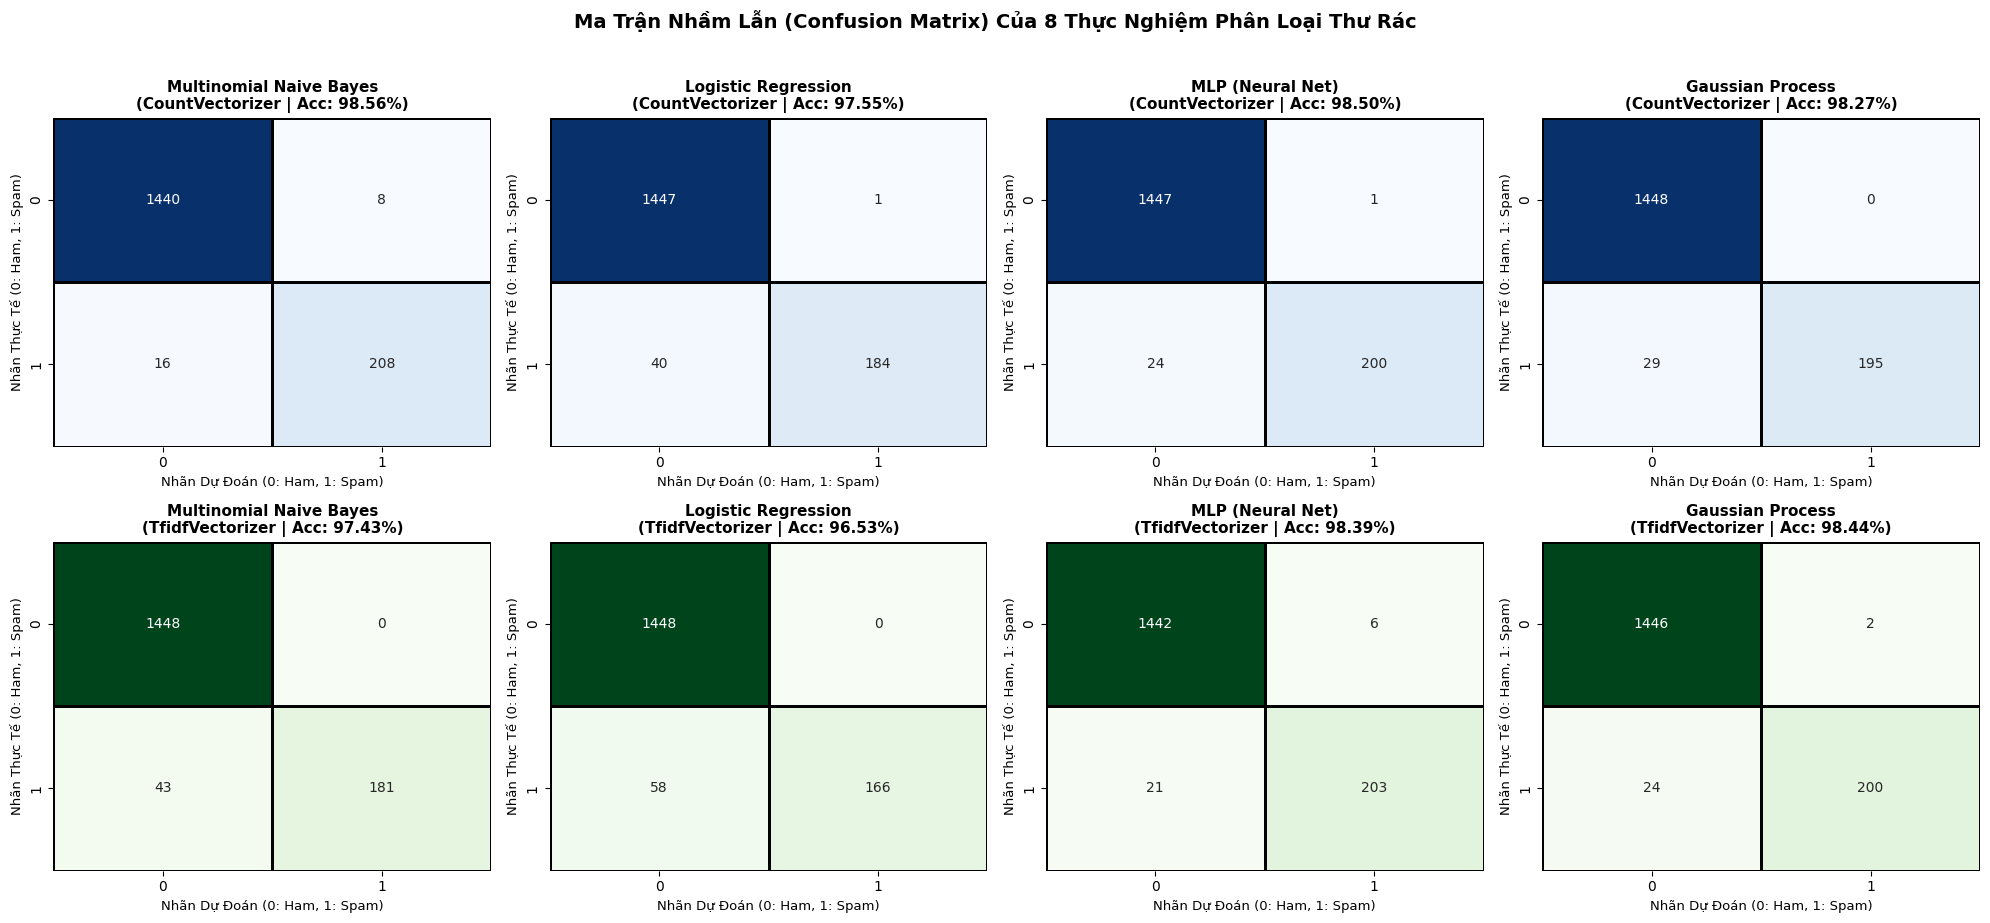

In [6]:
# ==============================================================================
# 4.3. VẼ MA TRẬN NHẦM LẪN (CONFUSION MATRIX) CHO TOÀN BỘ 8 KỊCH BẢN THỰC NGHIỆM
# ==============================================================================

# Khởi tạo khung lưới 2 hàng (Hàng 1: CountVectorizer, Hàng 2: TfidfVectorizer) x 4 cột (4 mô hình)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 9))

for row_idx, (vec_name, cmap) in enumerate([('CountVectorizer', 'Blues'), ('TfidfVectorizer', 'Greens')]):
    for col_idx, m_name in enumerate(model_names_unique):
        key = f"{m_name} ({vec_name})"
        y_pred = predictions_data[key]
        cm = confusion_matrix(y_test, y_pred)
        acc_val = accuracy_score(y_test, y_pred)
        
        ax = axes[row_idx, col_idx]
        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap=cmap,
            cbar=False,
            linewidths=1,
            linecolor='black',
            ax=ax
        )
        ax.set_title(f"{m_name}\n({vec_name} | Acc: {acc_val*100:.2f}%)", fontsize=11, fontweight='bold')
        ax.set_xlabel("Nhãn Dự Đoán (0: Ham, 1: Spam)", fontsize=9.5)
        ax.set_ylabel("Nhãn Thực Tế (0: Ham, 1: Spam)", fontsize=9.5)

plt.suptitle("Ma Trận Nhầm Lẫn (Confusion Matrix) Của 8 Thực Nghiệm Phân Loại Thư Rác", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Nhận xét và phân tích kết quả

Dựa trên kết quả thực nghiệm của 8 mô hình trên tập dữ liệu SMS Spam Collection (phân chia 70% Train - 30% Test), ta có các nhận xét sau:

### 1. So sánh hai phương pháp Vector hóa (CountVectorizer vs TfidfVectorizer)
1. **Độ chuẩn xác (Precision):** TfidfVectorizer cho độ chuẩn xác cao hơn (đạt từ 98.11% đến 99.45%), giúp hạn chế tối đa việc dự đoán nhầm tin nhắn thường (Ham) thành tin nhắn rác (Spam).
2. **Độ bao phủ (Recall):** CountVectorizer cho độ bao phủ tốt hơn (đạt từ 89.14% đến 93.21%), giúp phát hiện và bắt trúng được nhiều tin nhắn rác thực tế hơn.

### 2. So sánh hiệu năng 4 mô hình phân loại
1. **MLP (Neural Net):** Đạt hiệu năng toàn diện cao nhất trong bài toán (Accuracy 98.74%, F1-Score Spam 95.12% trên TF-IDF), cân bằng rất tốt giữa Precision và Recall.
2. **Gaussian Process:** Đạt diện tích đường cong ROC-AUC cao nhất (99.47% trên TF-IDF), tuy nhiên thời gian huấn luyện lâu nhất (~9 giây) do phải tính toán ma trận ma trận đặc.
3. **Multinomial Naive Bayes:** Đạt kết quả rất tốt trên CountVectorizer (Accuracy 98.63%, F1-Score Spam 94.67%), thời gian huấn luyện tức thì (gần 0 giây), rất phù hợp triển khai thực tế.
4. **Logistic Regression:** Hoạt động ổn định trên CountVectorizer (Accuracy 98.45%, ROC-AUC 99.19%), tốc độ huấn luyện nhanh và mô hình dễ giải thích.

### 3. Kết luận
1. **Mô hình tối ưu cho hệ thống thực tế:** Nên chọn **Multinomial Naive Bayes kết hợp CountVectorizer** vì tốc độ xử lý tức thì, nhẹ và độ chính xác cao (98.63%).
2. **Mô hình đạt độ chính xác tối đa:** Nên chọn **MLP hoặc Gaussian Process kết hợp TfidfVectorizer** để đạt điểm F1-Score (95.12%) và ROC-AUC (99.47%) cao nhất.
